# Does the two-thumb typing gap vary with age?

Mike Deng · STAT 5200

In the replication I compared typing speed by age and by typing posture separately. Here I ask whether the speed difference between two-thumb and one-thumb typists is larger at some ages than others. The outcome is words per minute (WPM) from the same mobile typing task.

This notebook reuses the [replication notebook’s data preparation](replication.ipynb) and the [existing extension code](typing37k/extension.py). It reads the verified Aalto files in `data/raw/` and fits the models from scratch. Open it from the repository root and select **Run All**.

[Extension report](docs/extension.md) · [Aalto data release](https://userinterfaces.aalto.fi/typing37k/)

## 1. Build the sample

After applying the replication’s cleaning rules, I keep volunteers aged 10–59 who reported typing with two thumbs or with a single thumb. I pool left and right single-thumb users. There are only eight one-thumb users below age 10 and six at 60 or above. Every eligible participant has the fields needed for the primary model.

The English typing frequency field follows the authors’ convention of coding blank responses as native English. Keyboard type and keyboard layout are separate fields.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib
matplotlib.use("Agg")

import pandas as pd
from IPython.display import Image, display

from typing37k.__main__ import load_replication_notebook
from typing37k.extension import run_extension

replication = load_replication_notebook()
participants, _ = replication.load_data(Path("data/raw"), offline=True)

## 2. Estimate the gap in each age band

I fit participant-level OLS with an indicator for two thumbs, indicators for five age bands, and interactions between the two-thumb indicator and the age-band indicators. I include categorical controls for reported keyboard type and English typing experience. The reference group is one-thumb typists aged 20–29.

```text
WPM ~ age_band * two_thumb + keyboard_type + English_typing_experience
```

The coefficient on two thumbs gives the adjusted gap for ages 20–29. For each other band, the gap is that coefficient plus the interaction coefficient for that band. I use HC3 standard errors for the 95% confidence intervals and for a joint F test of equal gaps across all five bands.

The cell below fits the primary and three sensitivity models. It reads their new outputs from a temporary folder and checks them against the aggregate tables committed to the repository.

In [2]:
with TemporaryDirectory(prefix="typing37k-extension-") as directory:
    output = Path(directory)
    run_extension(participants, output)
    tables = {}
    for path in sorted((output / "tables").glob("*.csv")):
        result = pd.read_csv(path)
        saved = pd.read_csv(Path("results/tables") / path.name)
        pd.testing.assert_frame_equal(result, saved, rtol=1e-7, atol=1e-9)
        tables[path.stem] = result
    gap_figure = (output / "figures/extension_age_gaps.png").read_bytes()

print(f"Regenerated and checked all {len(tables)} extension tables.")
sample_audit = tables["extension_sample_audit"]
audit = sample_audit.loc[sample_audit["model"].eq("primary")].drop(columns="model")
display(audit.rename(columns={"metric": "Sample step", "n": "Participants"}).reset_index(drop=True))

Regenerated and checked all 3 extension tables.


,Sample step,Participants
0,cleaned_sample,37370
1,eligible_age,37053
2,eligible_posture,31198
3,eligible_keyboard,31198
4,missing_wpm,0
5,missing_keyboard_type,0
6,missing_type_english,0
7,complete_cases,31198


## 3. Primary results

The raw gap is the difference in observed means within each age band. The adjusted gap comes from the OLS model. The confidence intervals describe uncertainty for each band separately.

,Age,One thumb,Two thumbs,Raw gap (WPM),Adjusted gap (WPM),95% CI lower,95% CI upper
0,10-19,773,9078,9.18,8.56,7.66,9.45
1,20-29,1874,13864,6.56,6.25,5.74,6.75
2,30-39,614,3609,5.40,5.09,4.31,5.88
3,40-49,207,905,5.51,6.07,4.89,7.26
4,50-59,73,201,5.60,5.31,2.65,7.96


Joint test of equal gaps: F(4, 31,178) = 8.57, p = 6.63e-07.


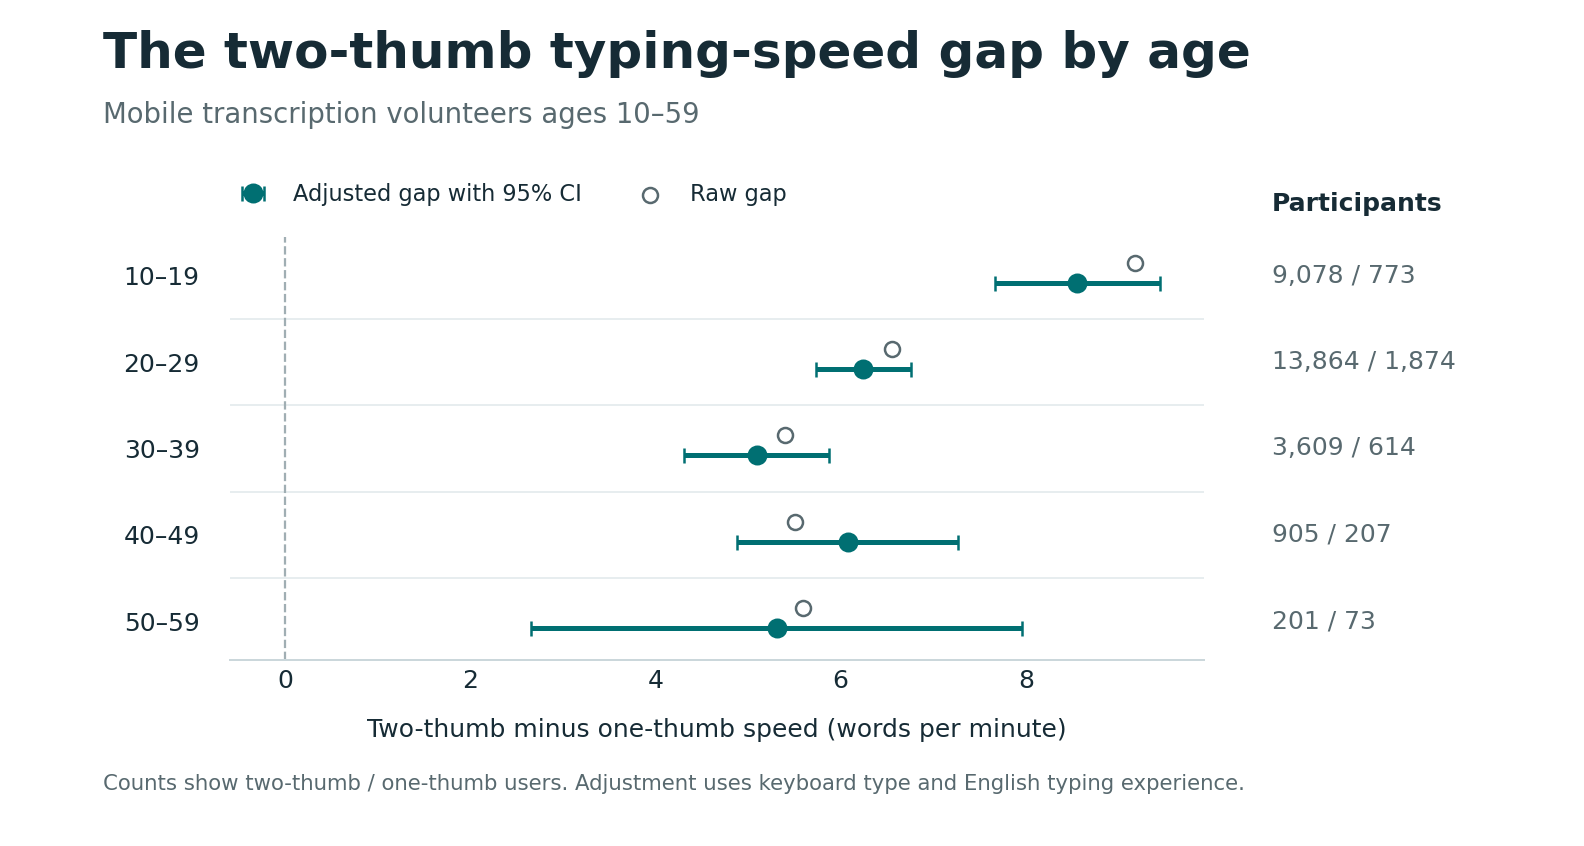

In [3]:
age_gaps = tables["extension_age_gaps"]
tests = tables["extension_interaction_tests"].set_index("model")
primary = age_gaps.loc[age_gaps["model"].eq("primary")]
columns = {
    "age_band": "Age",
    "n_comparison": "One thumb",
    "n_two_thumb": "Two thumbs",
    "raw_gap_wpm": "Raw gap (WPM)",
    "adjusted_gap_wpm": "Adjusted gap (WPM)",
    "ci95_low_wpm": "95% CI lower",
    "ci95_high_wpm": "95% CI upper",
}
display(primary[list(columns)].rename(columns=columns).round(2).reset_index(drop=True))

test = tests.loc["primary"]
print(
    f"Joint test of equal gaps: F({int(test.df_num)}, {int(test.df_denom):,})"
    f" = {test.f_statistic_hc3:.2f}, p = {test.p_value:.3g}."
)
display(Image(data=gap_figure, format="png"))

The adjusted gap is largest among ages 10–19, at **8.56 WPM**. It ranges from **5.09 to 6.25 WPM** across the adult bands. The joint test gives evidence that the gaps differ by age. The interval for ages 50–59 is the widest, and that group has only 73 one-thumb users.

## 4. Sensitivity checks

I add keyboard layout, restrict the sample to people who reported a mobile keyboard, and change the comparison group to the other five named postures. Each row below shows the estimate for ages 10–19 and the joint test across all five age bands.

In [4]:
model_labels = {
    "primary": "Primary",
    "plus_layout": "Add keyboard layout",
    "mobile_keyboard_only": "Reported mobile keyboards",
    "other_named_postures": "Other five named postures",
}
youngest = age_gaps.loc[age_gaps["age_band"].eq("10-19")].set_index("model")
sensitivity = tests[["n", "p_value"]].join(youngest[["adjusted_gap_wpm"]])
sensitivity = sensitivity.rename(index=model_labels, columns={
    "n": "Participants",
    "p_value": "Joint interaction p",
    "adjusted_gap_wpm": "Adjusted gap at ages 10–19 (WPM)",
})
display(sensitivity[["Participants", "Adjusted gap at ages 10–19 (WPM)", "Joint interaction p"]].round(2)
        .assign(**{"Joint interaction p": sensitivity["Joint interaction p"].map("{:.3g}".format)}))

,Participants,Adjusted gap at ages 10–19 (WPM),Joint interaction p
model,,,
Primary,31198,8.56,6.63e-07
Add keyboard layout,31198,8.18,7.83e-07
Reported mobile keyboards,28944,8.60,2.82e-06
Other five named postures,33524,7.66,6.28e-11


Ages 10–19 have the largest estimated gap in each model. Broadening the comparison group changes the question because it includes people who used their index fingers.

## 5. Interpretation

These estimates describe associations among volunteers copying English sentences. People chose and reported their typing posture. Practice, device features, and prior skill may differ even among people in the same modeled categories. A study that assigns posture within participant could better measure what happens when a person switches to typing with two thumbs.

[Replication notebook](replication.ipynb) · [Extension report](docs/extension.md)